In [1]:
# 0.1 Mount Drive + base packages
from google.colab import drive
drive.mount('/content/drive')
import os
WORK = "/content/drive/MyDrive/vi_inpaint_test"   # if you change this, change it in the %%writefile line below and in each Part header
os.makedirs(WORK, exist_ok=True)
!pip install -q silero-vad pesq pystoi jiwer

Mounted at /content/drive
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
%%writefile /content/drive/MyDrive/vi_inpaint_test/vi_inpaint_utils.py
# Shared helpers for all parts (written to Drive so every session can import them)
import json, os
import numpy as np
import soundfile as sf
import librosa, librosa.display
import scipy.ndimage as nd
import matplotlib.pyplot as plt

WORK = os.path.dirname(os.path.abspath(__file__))

def p(name):
    return os.path.join(WORK, name)

def load(path, sr):
    x, _ = librosa.load(path, sr=sr, mono=True)
    return x.astype(np.float32)

def save(path, x, sr):
    sf.write(path, np.asarray(x, dtype=np.float32), sr)

def load_meta():
    with open(p("meta.json"), encoding="utf-8") as f:
        return json.load(f)

def save_meta(m):
    with open(p("meta.json"), "w", encoding="utf-8") as f:
        json.dump(m, f, ensure_ascii=False, indent=2)

def out_dir(meta):
    d = p("outputs_" + meta.get("mask_source", "gt"))
    os.makedirs(d, exist_ok=True)
    return d

def fit_len(x, n):
    x = np.asarray(x, dtype=np.float32)
    return x[:n] if len(x) >= n else np.pad(x, (0, n - len(x)))

def splice(base, gen, spans, sr, xfade_ms=15):
    """Replace base[span] with gen[span] (time-aligned), with short linear crossfades."""
    base = np.asarray(base, dtype=np.float32).copy()
    gen = fit_len(gen, len(base))
    f = int(sr * xfade_ms / 1000)
    for s, e in spans:
        a, b = max(0, int(round(s * sr))), min(len(base), int(round(e * sr)))
        if b <= a:
            continue
        seg = gen[a:b].copy()
        if f > 0 and (b - a) > 2 * f:
            r = np.linspace(0, 1, f, dtype=np.float32)
            seg[:f] = base[a:a + f] * (1 - r) + seg[:f] * r
            seg[-f:] = seg[-f:] * (1 - r) + base[b - f:b] * r
        base[a:b] = seg
    return base

def synth_noise(n, sr, rng):
    """Street-like burst: pink noise + horn-like harmonics + engine buzz."""
    t = np.arange(n) / sr
    X = np.fft.rfft(rng.standard_normal(n))
    f = np.fft.rfftfreq(n, 1 / sr)
    X[1:] /= np.sqrt(f[1:]); X[0] = 0
    pink = np.fft.irfft(X, n); pink /= pink.std() + 1e-9
    horn = sum(np.sin(2 * np.pi * f0 * t + rng.uniform(0, 6.28)) for f0 in (415, 520, 830, 1040, 1245))
    horn = horn * (1 + 0.2 * np.sin(2 * np.pi * 7 * t)); horn /= horn.std() + 1e-9
    engine = np.sign(np.sin(2 * np.pi * 38 * t)); engine /= engine.std() + 1e-9
    x = 0.6 * pink + 0.6 * horn + 0.3 * engine
    return (x / (x.std() + 1e-9)).astype(np.float32)

def add_bursts(clean, noise, bursts, sr, rng, fade_ms=10):
    """bursts: [(start_s, dur_s, local_snr_db)]. Local SNR is measured against the clean speech under the burst."""
    noisy = clean.astype(np.float32).copy()
    act = clean[np.abs(clean) > 0.02 * np.abs(clean).max()]
    p_glob = float(np.mean(act ** 2)) if len(act) else float(np.mean(clean ** 2))
    spans = []
    for start, d, snr in bursts:
        n = int(d * sr)
        a = int(max(0, min(int(start * sr), len(clean) - n)))
        ps = float(np.mean(clean[a:a + n] ** 2))
        if ps < 0.1 * p_glob:
            ps = p_glob
        off = int(rng.integers(0, max(1, len(noise) - n)))
        nz = np.resize(noise[off:off + n], n).astype(np.float32)
        nz *= np.sqrt(ps / ((np.mean(nz ** 2) + 1e-12) * 10 ** (snr / 10)))
        fl = int(sr * fade_ms / 1000)
        w = np.ones(n, dtype=np.float32); r = np.linspace(0, 1, fl, dtype=np.float32)
        w[:fl] = r; w[-fl:] = r[::-1]
        noisy[a:a + n] += nz * w
        spans.append([round(a / sr, 3), round((a + n) / sr, 3)])
    scale = 1.0
    peak = float(np.abs(noisy).max())
    if peak > 0.99:
        scale = 0.99 / peak
    return noisy * scale, spans, scale

def mask_to_spans(mask, hop, pad=0.0, min_len=0.0, merge_gap=0.0, dur=None):
    lab, n = nd.label(mask)
    spans = []
    for k in range(1, n + 1):
        idx = np.where(lab == k)[0]
        spans.append([float(idx[0] * hop), float((idx[-1] + 1) * hop)])
    merged = []
    for s, e in spans:
        if merged and s - merged[-1][1] < merge_gap:
            merged[-1][1] = e
        else:
            merged.append([s, e])
    dur = dur if dur is not None else (len(mask) * hop)
    return [[round(max(0.0, s - pad), 3), round(min(dur, e + pad), 3)] for s, e in merged if e - s >= min_len]

def span_mask(spans, n, sr, pad=0.0):
    m = np.zeros(n, dtype=bool)
    for s, e in spans:
        m[max(0, int((s - pad) * sr)):min(n, int((e + pad) * sr))] = True
    return m

def span_iou(a, b, dur, res=0.01):
    n = int(dur / res) + 1
    ma, mb = span_mask(a, n, 1 / res), span_mask(b, n, 1 / res)
    u = (ma | mb).sum()
    return float((ma & mb).sum() / u) if u else 1.0

def sisdr(ref, est, eps=1e-9):
    ref = ref - ref.mean(); est = est - est.mean()
    a = np.dot(est, ref) / (np.dot(ref, ref) + eps)
    t = a * ref
    return float(10 * np.log10((np.sum(t ** 2) + eps) / (np.sum((est - t) ** 2) + eps)))

def plot_spec(ax, x, sr, title="", spans=None, gt=None, xlim=None):
    S = librosa.amplitude_to_db(np.abs(librosa.stft(x, n_fft=1024, hop_length=256)), ref=np.max)
    librosa.display.specshow(S, sr=sr, hop_length=256, x_axis="time", y_axis="hz", ax=ax, cmap="magma", vmin=-80)
    for s, e in (gt or []):
        ax.axvspan(s, e, ymin=0.92, ymax=1.0, color="lime", alpha=0.9)
    for s, e in (spans or []):
        ax.axvline(s, color="cyan", lw=1.2); ax.axvline(e, color="cyan", lw=1.2)
    if xlim:
        ax.set_xlim(*xlim)
    ax.set_title(title, fontsize=10); ax.set_xlabel("")

Writing /content/drive/MyDrive/vi_inpaint_test/vi_inpaint_utils.py


In [5]:
# 0.2 Inputs
import sys, json, numpy as np, torch, librosa
sys.path.insert(0, WORK)
import importlib, vi_inpaint_utils as U; importlib.reload(U)
from IPython.display import Audio, display

CLEAN_PATH = None   # e.g. "/content/drive/MyDrive/data/vivos_test_xxx.wav"; None -> upload a file
TRANSCRIPT = "TIẾNG CỌC CẠCH KHỰNG LẠI CỦA NHỮNG KHỚP SẮT"     # exact transcript of the clean utterance (Vietnamese)
NOISE_PATH = None   # a real noise recording (motorbike, horn, market...); None -> synthetic street burst
BURSTS = None       # [(start_s, dur_s, local_snr_db), ...]; None -> 2 bursts of 0.5 s at -5 dB on top of speech
SEED = 0

if CLEAN_PATH is None:
    from google.colab import files
    up = files.upload()
    CLEAN_PATH = os.path.abspath(next(iter(up)))
assert TRANSCRIPT.strip(), "Set TRANSCRIPT to the exact transcript of the clean file"

SR = 24000
clean24 = U.load(CLEAN_PATH, SR)
clean24 = 0.5 * clean24 / (np.abs(clean24).max() + 1e-9)
print(f"clean: {len(clean24)/SR:.2f} s")
if not 4 <= len(clean24)/SR <= 15:
    print("⚠️  4–15 s works best (F5-TTS max ~30 s; MaskGCT needs some left context as voice prompt)")

Saving VIVOSDEV01_R002.wav to VIVOSDEV01_R002 (1).wav
clean: 4.06 s


In [6]:
# 0.3 Add noise bursts at known positions (ground-truth "too noisy" spans)
from silero_vad import load_silero_vad, get_speech_timestamps
rng = np.random.default_rng(SEED)
dur = len(clean24) / SR
noise = U.load(NOISE_PATH, SR) if NOISE_PATH else U.synth_noise(int(3 * SR), SR, rng)

vad = load_silero_vad()
clean16 = librosa.resample(clean24, orig_sr=SR, target_sr=16000)
ts = get_speech_timestamps(torch.from_numpy(clean16), vad, sampling_rate=16000, return_seconds=True)
print("speech regions in clean:", [(round(t['start'], 2), round(t['end'], 2)) for t in ts])

if BURSTS is None:
    BURSTS = [(round(f * dur - 0.25, 2), 0.5, -5.0) for f in (0.35, 0.65)]
noisy24, gt_spans, scale = U.add_bursts(clean24, noise, BURSTS, SR, rng)
clean24 = clean24 * scale   # keep clean and noisy at the same level
noisy16 = librosa.resample(noisy24, orig_sr=SR, target_sr=16000)

U.save(U.p("clean_24k.wav"), clean24, SR)
U.save(U.p("noisy_24k.wav"), noisy24, SR)
U.save(U.p("noisy_16k.wav"), noisy16, 16000)
meta = dict(transcript=TRANSCRIPT.strip(), gt_spans=gt_spans, bursts=BURSTS, dur=dur, source=CLEAN_PATH)
U.save_meta(meta)
print("ground-truth noisy spans:", gt_spans)
print("clean:"); display(Audio(clean24, rate=SR))
print("noisy:"); display(Audio(noisy24, rate=SR))

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


speech regions in clean: [(0.7, 4.06)]
ground-truth noisy spans: [[1.17, 1.67], [2.39, 2.89]]
clean:


noisy:


100%|██████████| 28.2M/28.2M [00:00<00:00, 150MB/s]


detected spans: [[0.96, 1.7], [1.88, 2.08], [2.14, 2.92], [3.16, 3.52]]
ground truth  : [[1.17, 1.67], [2.39, 2.89]]
IoU detected vs gt: 0.48


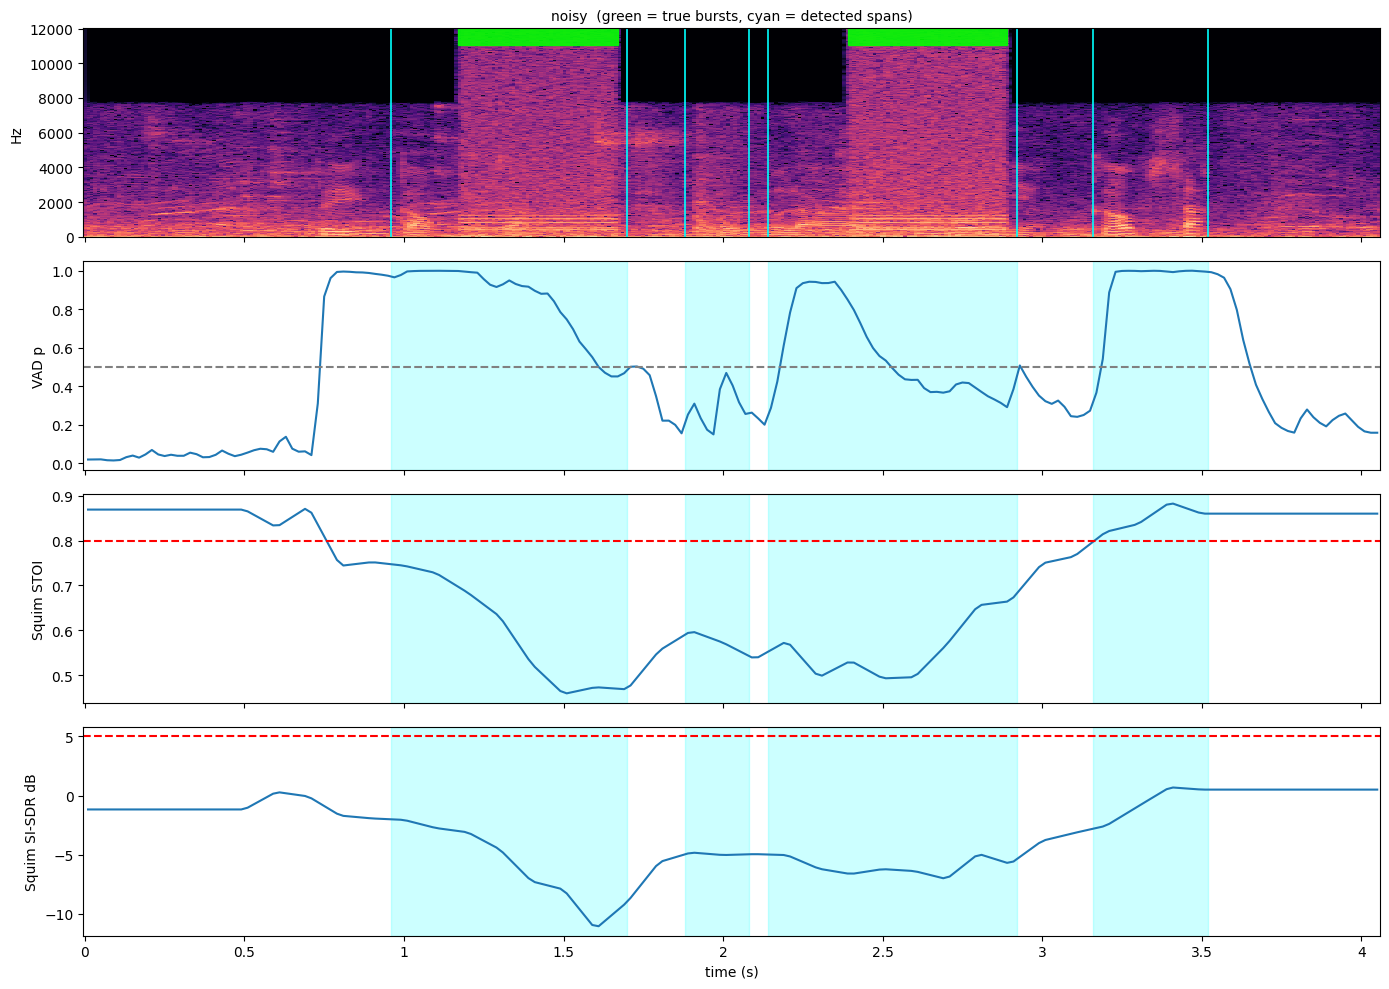

In [8]:
# 0.4 Tier A detection
import torchaudio, scipy.ndimage as nd, matplotlib.pyplot as plt
dev = "cuda" if torch.cuda.is_available() else "cpu"

SISDR_THR = 5.0     # dB: Squim-estimated SI-SDR below this = too noisy
STOI_THR  = 0.80    # Squim-estimated STOI below this = too noisy
REFINE_DB = 3.0     # keep frames this many dB above the median speech-frame energy
WIN, STEP, HOP = 1.0, 0.1, 0.02
MIN_SPAN, MERGE_GAP, PAD = 0.10, 0.10, 0.04

x, sr = noisy16, 16000
nF = int(dur / HOP); t = (np.arange(nF) + 0.5) * HOP

# (1) VAD probability, 32 ms chunks
vad.reset_states()
xt = torch.from_numpy(x)
probs = [vad(xt[i:i + 512], sr).item() for i in range(0, len(xt) - 511, 512)]
vad_p = np.interp(t, (np.arange(len(probs)) + 0.5) * 512 / sr, probs)

# (2) Squim objective (est. STOI / PESQ / SI-SDR) on a sliding window
squim = torchaudio.pipelines.SQUIM_OBJECTIVE.get_model().to(dev).eval()
cen, st_l, sd_l = [], [], []
with torch.no_grad():
    for s in np.arange(0, max(dur - WIN, 0) + 1e-6, STEP):
        seg = torch.from_numpy(x[int(s * sr):int((s + WIN) * sr)])[None].to(dev)
        stoi_e, pesq_e, sisdr_e = squim(seg)
        cen.append(s + WIN / 2); st_l.append(stoi_e.item()); sd_l.append(sisdr_e.item())
stoi_p, sisdr_p = np.interp(t, cen, st_l), np.interp(t, cen, sd_l)

# (3) frame energy
fl = int(HOP * sr)
E = np.array([10 * np.log10(np.mean(x[i * fl:(i + 1) * fl] ** 2) + 1e-10) for i in range(nF)])

speech_ctx = nd.binary_dilation(vad_p > 0.5, iterations=int(0.3 / HOP))
coarse = speech_ctx & ((sisdr_p < SISDR_THR) | (stoi_p < STOI_THR))
ref_frames = (vad_p > 0.5) & ~coarse
refE = np.median(E[ref_frames]) if ref_frames.sum() > 10 else np.median(E)
fine = nd.binary_closing(coarse & (E - refE > REFINE_DB), iterations=3)
lab, nlab = nd.label(coarse)
final = np.zeros_like(coarse)
for k in range(1, nlab + 1):
    reg = lab == k
    final |= (fine & reg) if (fine & reg).any() else reg

det_spans = U.mask_to_spans(final, HOP, pad=PAD, min_len=MIN_SPAN, merge_gap=MERGE_GAP, dur=dur)
print("detected spans:", det_spans)
print("ground truth  :", meta["gt_spans"])
print(f"IoU detected vs gt: {U.span_iou(det_spans, meta['gt_spans'], dur):.2f}")

fig, ax = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
U.plot_spec(ax[0], noisy24, 24000, "noisy  (green = true bursts, cyan = detected spans)", det_spans, meta["gt_spans"])
ax[1].plot(t, vad_p); ax[1].set_ylabel("VAD p"); ax[1].axhline(0.5, ls="--", c="gray")
ax[2].plot(t, stoi_p); ax[2].axhline(STOI_THR, ls="--", c="r"); ax[2].set_ylabel("Squim STOI")
ax[3].plot(t, sisdr_p); ax[3].axhline(SISDR_THR, ls="--", c="r"); ax[3].set_ylabel("Squim SI-SDR dB")
for a in ax[1:]:
    for s, e in det_spans: a.axvspan(s, e, color="cyan", alpha=0.2)
ax[3].set_xlabel("time (s)"); plt.tight_layout(); plt.show()

In [11]:
def span_metrics(pred, gt, dur, res=0.01, cover=0.5):
    n = int(round(dur / res)) + 1
    def mk(spans):
        m = np.zeros(n, bool)
        for s, e in spans:
            m[int(round(s / res)):int(round(e / res))] = True
        return m
    P, G = mk(pred), mk(gt)
    tp, fp, fn = int((P & G).sum()), int((P & ~G).sum()), int((~P & G).sum())
    prec = tp / (tp + fp) if tp + fp else float(not G.any())
    rec = tp / (tp + fn) if tp + fn else 1.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    iou = tp / (tp + fp + fn) if tp + fp + fn else 1.0
    found = [P[int(round(s/res)):int(round(e/res))].mean() >= cover for s, e in gt]
    right = [G[int(round(s/res)):int(round(e/res))].mean() >= cover for s, e in pred]
    frag = [sum(1 for s, e in pred if min(e, ge) > max(s, gs)) for gs, ge in gt]
    return dict(frame_precision=prec, frame_recall=rec, frame_f1=f1, frame_iou=iou,
                span_recall=float(np.mean(found)) if found else 1.0,
                span_precision=float(np.mean(right)) if right else 1.0,
                pred_spans_per_gt_span=frag, missed_s=fn*res, extra_s=fp*res)

print(span_metrics(det_spans, meta["gt_spans"], dur))

NameError: name 'det_spans' is not defined

In [9]:
# 0.5 Choose which spans the inpainters fill + "zeroed" baseline
MASK_SOURCE = "gt"   # "gt" = oracle burst positions (test the inpainters alone) | "detected" = Tier A output

spans = meta["gt_spans"] if MASK_SOURCE == "gt" else det_spans
assert spans, "No spans to inpaint: lower the thresholds in 0.4 or use MASK_SOURCE='gt'"
for s, e in spans:
    if e - s > 1.5:
        print(f"⚠️  span {s}-{e} is {e-s:.2f} s long; inpainting quality drops sharply above ~1 s")
meta.update(det_spans=det_spans, spans=spans, mask_source=MASK_SOURCE)
U.save_meta(meta)
OUT = U.out_dir(meta)
U.save(os.path.join(OUT, "zeroed.wav"), U.splice(noisy24, np.zeros_like(noisy24), spans, SR), SR)
print("spans to inpaint:", spans, "| outputs ->", OUT)

spans to inpaint: [[1.17, 1.67], [2.39, 2.89]] | outputs -> /content/drive/MyDrive/vi_inpaint_test/outputs_gt


In [10]:
# 1.1 Install
!pip install -q f5-tts

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [11]:
# 1.2 Load model
import os, sys, shutil, numpy as np, torch
from google.colab import drive; drive.mount('/content/drive')
sys.path.insert(0, "/content/drive/MyDrive/vi_inpaint_test"); import vi_inpaint_utils as U
from IPython.display import Audio, display
from importlib.resources import files
from omegaconf import OmegaConf
from huggingface_hub import hf_hub_download
from f5_tts.model import CFM, DiT
from f5_tts.model.utils import get_tokenizer, convert_char_to_pinyin
from f5_tts.infer.utils_infer import load_checkpoint, load_vocoder

dev = "cuda"
REPO = "hynt/F5-TTS-Vietnamese-ViVoice"
ckpt = hf_hub_download(REPO, "model_last.pt")
vocab = "/content/f5_vi_vocab.txt"
shutil.copy(hf_hub_download(REPO, "config.json"), vocab)   # this repo's "config.json" is actually the vocab list (see its model card)

cfg = OmegaConf.load(str(files("f5_tts").joinpath("configs/F5TTS_Base.yaml")))
mel = cfg.model.mel_spec
vocab_map, vocab_size = get_tokenizer(vocab, "custom")
model = CFM(
    transformer=DiT(**cfg.model.arch, text_num_embeds=vocab_size, mel_dim=mel.n_mel_channels),
    mel_spec_kwargs=dict(n_fft=mel.n_fft, hop_length=mel.hop_length, win_length=mel.win_length,
                         n_mel_channels=mel.n_mel_channels, target_sample_rate=mel.target_sample_rate,
                         mel_spec_type=mel.mel_spec_type),
    odeint_kwargs=dict(method="euler"),
    vocab_char_map=vocab_map,
).to(dev)
model = load_checkpoint(model, ckpt, dev, use_ema=True)
vocoder = load_vocoder("vocos", is_local=False, device=dev)
SR, HOPL = mel.target_sample_rate, mel.hop_length
print("loaded; sr =", SR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:300: SyntaxWarning: invalid escape sequence '\('
  m = re.match('([su]([0-9]{1,2})p?) \(([0-9]{1,2}) bit\)$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:301: SyntaxWarning: invalid escape sequence '\('
  m2 = re.match('([su]([0-9]{1,2})p?)( \(default\))?$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:310: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(flt)p?( \(default\))?$', token):
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:314: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(dbl)p?( \(default\))?$', token):


model_last.pt: reconstructing file:   0%|          |  0.00B / 5.39GB            

model_last.pt: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/11.3k [00:00<?, ?B/s]

Download Vocos from huggingface charactr/vocos-mel-24khz


config.yaml:   0%|          | 0.00/461 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 54.4MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

loaded; sr = 24000


In [12]:
# 1.3 Inpaint the spans
ASR_HYP = ""                 # optional: paste your ASR's output on noisy_16k.wav here
NFE, CFG, SEED = 32, 2.0, 0

meta = U.load_meta(); spans = meta["spans"]; OUT = U.out_dir(meta)
x = U.load(U.p("noisy_24k.wav"), SR)
audio = torch.from_numpy(x)[None].to(dev)
rms = audio.pow(2).mean().sqrt().item(); target_rms = 0.1
if rms < target_rms:
    audio = audio * target_rms / rms

with torch.inference_mode():
    mel_full = model.mel_spec(audio).permute(0, 2, 1)          # [1, T, 100]
T = mel_full.shape[1]
edit_mask = torch.ones(1, T, dtype=torch.bool, device=dev)     # True = keep
mel_cond = mel_full.clone()
for s, e in spans:
    a, b = round(s * SR / HOPL), min(T, round(e * SR / HOPL))
    edit_mask[:, a:b] = False
    mel_cond[:, a:b] = 0

modes = {"gt": meta["transcript"], "none": " "}
if ASR_HYP.strip():
    modes["asr"] = ASR_HYP
for name, text in modes.items():
    with torch.inference_mode():
        gen, _ = model.sample(cond=mel_cond, text=convert_char_to_pinyin([text.lower()]), duration=T,
                              steps=NFE, cfg_strength=CFG, sway_sampling_coef=-1.0, seed=SEED, edit_mask=edit_mask)
        wav = vocoder.decode(gen.float().permute(0, 2, 1)).squeeze().cpu().numpy()
    if rms < target_rms:
        wav = wav * rms / target_rms
    out = U.splice(x, wav, spans, SR)
    U.save(os.path.join(OUT, f"f5_{name}.wav"), out, SR)
    print(f"F5 text={name!r}"); display(Audio(out, rate=SR))

F5 text='gt'


F5 text='none'


In [19]:
# 2.1 Install. transformers 4.45.2 is the newest release whose Llama layer still accepts Amphion's custom decoder-layer call
# (4.46+ makes position_embeddings mandatory). tokenizers 0.20.3 ships prebuilt wheels for Python 3.13, so nothing is compiled.
%cd /content
![ -d Amphion ] || git clone -q --depth 1 https://github.com/open-mmlab/Amphion.git
!pip install -q --only-binary=tokenizers "tokenizers==0.20.3" "transformers==4.45.2" json5 einops six safetensors
print("\n>>> Install done. REQUIRED: Runtime -> Restart session now, then SKIP this cell and run 2.2 (files stay on disk; the old transformers is still loaded in memory).")

/content

>>> Install done. REQUIRED: Runtime -> Restart session now, then SKIP this cell and run 2.2 (files stay on disk; the old transformers is still loaded in memory).


In [2]:
!pip install -q ruamel.yaml

In [3]:
# 2.2 Load model components (S2A path only, so the G2P dependencies are not needed)
import os, sys, numpy as np, torch, librosa
from google.colab import drive; drive.mount('/content/drive')
sys.path.insert(0, "/content/drive/MyDrive/vi_inpaint_test"); import vi_inpaint_utils as U
from IPython.display import Audio, display
os.chdir("/content/Amphion"); sys.path.insert(0, "/content/Amphion")

import safetensors.torch as st
from huggingface_hub import hf_hub_download
from transformers import Wav2Vec2BertModel, SeamlessM4TFeatureExtractor
from utils.util import load_config
from models.codec.kmeans.repcodec_model import RepCodec
from models.tts.maskgct.maskgct_s2a import MaskGCT_S2A
from models.codec.amphion_codec.codec import CodecEncoder, CodecDecoder

dev = "cuda"
cfg = load_config("./models/tts/maskgct/config/maskgct.json")
proc = SeamlessM4TFeatureExtractor.from_pretrained("facebook/w2v-bert-2.0")
w2v = Wav2Vec2BertModel.from_pretrained("facebook/w2v-bert-2.0").eval().to(dev)
stats = torch.load("./models/tts/maskgct/ckpt/wav2vec2bert_stats.pt")
sem_mean, sem_std = stats["mean"].to(dev), torch.sqrt(stats["var"]).to(dev)

sem_codec = RepCodec(cfg=cfg.model.semantic_codec).eval().to(dev)
enc = CodecEncoder(cfg=cfg.model.acoustic_codec.encoder).eval().to(dev)
dec = CodecDecoder(cfg=cfg.model.acoustic_codec.decoder).eval().to(dev)
s2a_1 = MaskGCT_S2A(cfg=cfg.model.s2a_model.s2a_1layer).eval().to(dev)
s2a_f = MaskGCT_S2A(cfg=cfg.model.s2a_model.s2a_full).eval().to(dev)
g = lambda f: hf_hub_download("amphion/MaskGCT", filename=f)
st.load_model(sem_codec, g("semantic_codec/model.safetensors"))
st.load_model(enc, g("acoustic_codec/model.safetensors"))
st.load_model(dec, g("acoustic_codec/model_1.safetensors"))
st.load_model(s2a_1, g("s2a_model/s2a_model_1layer/model.safetensors"))
st.load_model(s2a_f, g("s2a_model/s2a_model_full/model.safetensors"))
print("MaskGCT S2A loaded")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/275 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/2.32G [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


... (2 outputs left out)

acoustic_codec/model_1.safetensors:   0%|          | 0.00/513M [00:00<?, ?B/s]

s2a_model/s2a_model_1layer/model.safeten(…):   0%|          | 0.00/1.32G [00:00<?, ?B/s]

s2a_model/s2a_model_full/model.safetenso(…):   0%|          | 0.00/1.41G [00:00<?, ?B/s]

MaskGCT S2A loaded


In [4]:
# 2.3 Regenerate each span
@torch.no_grad()
def semantic_codes(w16):
    inp = proc(w16, sampling_rate=16000, return_tensors="pt")
    out = w2v(input_features=inp["input_features"].to(dev), attention_mask=inp["attention_mask"].to(dev),
              output_hidden_states=True)
    feat = (out.hidden_states[17] - sem_mean) / sem_std
    code, _ = sem_codec.quantize(feat)
    return code[:, : int(round(len(w16) / 320))]                # [1, T] at 50 Hz

@torch.no_grad()
def acoustic_codes(w24):
    emb = enc(torch.from_numpy(w24).to(dev)[None, None])
    _, vq, _, _, _ = dec.quantizer(emb)
    return vq.permute(1, 2, 0)                                    # [1, T, 12] at 50 Hz

@torch.no_grad()
def s2a(sem, prompt, steps=(25, 10, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1), cfg_w=2.5, rescale=0.75):
    steps = list(steps)
    p1 = s2a_1.reverse_diffusion(cond=s2a_1.cond_emb(sem), prompt=prompt, temp=1.5, filter_thres=0.98,
                                 n_timesteps=steps[:1], cfg=cfg_w, rescale_cfg=rescale)
    pf = s2a_f.reverse_diffusion(cond=s2a_f.cond_emb(sem), prompt=prompt, temp=1.5, filter_thres=0.98,
                                 n_timesteps=steps, cfg=cfg_w, rescale_cfg=rescale, gt_code=p1)
    return dec(dec.vq2emb(pf.permute(2, 0, 1), n_quantizers=12))[0, 0].cpu().numpy()

torch.manual_seed(0)
meta = U.load_meta(); spans = meta["spans"]; OUT = U.out_dir(meta)
noisy24 = U.load(U.p("noisy_24k.wav"), 24000)
cur = noisy24.copy()
for s, e in spans:
    a_fr, b_fr = int(np.floor(s * 50)), int(np.ceil(e * 50))
    if a_fr < 10:
        print(f"skip span {s}-{e}: needs at least 0.2 s of left context"); continue
    if a_fr < 25:
        print(f"⚠️  span {s}-{e}: only {a_fr/50:.2f} s of left context as voice prompt")
    prompt = acoustic_codes(cur[: a_fr * 480])
    P = prompt.shape[1]
    cur16 = librosa.resample(cur, orig_sr=24000, target_sr=16000)
    sem = semantic_codes(cur16[: b_fr * 320])
    G = min(b_fr - a_fr, sem.shape[1] - P)
    gen = s2a(sem[:, : P + G], prompt)                            # audio for the gap only
    full = cur.copy()
    full[P * 480 : P * 480 + len(gen)] = gen[: len(full) - P * 480]
    cur = U.splice(cur, full, [[P / 50, (P + G) / 50]], 24000)
    print(f"span {s}-{e}: prompt {P/50:.2f}s, regenerated {G/50:.2f}s")

U.save(os.path.join(OUT, "maskgct.wav"), cur, 24000)
display(Audio(cur, rate=24000))

The attention layers in this model are transitioning from computing the RoPE embeddings internally through `position_ids` (2D tensor with the indexes of the tokens), to using externally computed `position_embeddings` (Tuple of tensors, containing cos and sin). In v4.46 `position_ids` will be removed and `position_embeddings` will be mandatory.


span 1.17-1.67: prompt 1.16s, regenerated 0.50s
span 2.39-2.89: prompt 2.38s, regenerated 0.50s


In [5]:
# 3.1 Install
!apt-get -qq install -y espeak-ng > /dev/null
%cd /content
![ -d VoiceCraft ] || git clone -q https://github.com/jasonppy/VoiceCraft.git
!pip install -q --no-deps "audiocraft @ git+https://github.com/facebookresearch/audiocraft.git@c5157b5bf14bf83449c17ea1eeb66c19fb4bc7f0"
!pip install -q phonemizer==3.2.1 flashy hydra-core hydra_colorlog julius num2words av torchmetrics encodec sentencepiece spacy einops
print("\n>>> Install done. If the next cell raises an ImportError, do Runtime -> Restart session, skip this cell, and rerun the next one.")

/content
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
audiocraft 1.0.0 requires demucs, which is not installed.
audiocraft 1.0.0 requires xformers, which is not installed.
audiocraft 1.0.0 requires spacy==3.5.2, but you have spacy 3.8.18 which is incompatible.

>>> Install done. If the next cell raises an ImportError, do Runtime -> Restart session, skip this cell, and rerun the next one.


In [2]:
!git clone -q https://github.com/facebookresearch/audiocraft.git /content/audiocraft_src
!cd /content/audiocraft_src && git checkout -q c5157b5bf14bf83449c17ea1eeb66c19fb4bc7f0
import importlib.util, os, shutil
pkg = importlib.util.find_spec("audiocraft").submodule_search_locations[0]
shutil.copytree("/content/audiocraft_src/config", os.path.join(os.path.dirname(pkg), "config"), dirs_exist_ok=True)

'/usr/local/lib/python3.13/dist-packages/config'

In [6]:
# 3.2 Load
import os, sys, numpy as np, torch, librosa
os.environ.setdefault("USER", "colab")   # audiocraft's Hydra config reads ${oc.env:USER}; Colab does not define it
from google.colab import drive; drive.mount('/content/drive')
sys.path.insert(0, "/content/drive/MyDrive/vi_inpaint_test"); import vi_inpaint_utils as U
from IPython.display import Audio, display
try:
    import xformers  # noqa: F401
except ImportError:  # audiocraft imports xformers.ops at module level but only uses it if asked to
    os.makedirs("/content/stubs/xformers", exist_ok=True)
    open("/content/stubs/xformers/__init__.py", "w").close()
    open("/content/stubs/xformers/ops.py", "w").close()
    sys.path.insert(0, "/content/stubs")
os.chdir("/content/VoiceCraft"); sys.path.insert(0, "/content/VoiceCraft")
from huggingface_hub import hf_hub_download
from data.tokenizer import AudioTokenizer, TextTokenizer, tokenize_text
from models import voicecraft

dev = "cuda"
model = voicecraft.VoiceCraft.from_pretrained("pyp1/VoiceCraft_giga830M").to(dev).eval()
phn2num = model.args.phn2num
# PyTorch >= 2.6 defaults to torch.load(weights_only=True), which rejects this checkpoint (it pickles an omegaconf config).
# We allow full unpickling for this ONE file only: it comes from the official pyp1/VoiceCraft repo. Don't do this for files you don't trust.
import functools
_orig_load = torch.load
torch.load = functools.partial(_orig_load, weights_only=False)
try:
    audio_tok = AudioTokenizer(signature=hf_hub_download("pyp1/VoiceCraft", "encodec_4cb2048_giga.th"))
finally:
    torch.load = _orig_load
text_tok = TextTokenizer(backend="espeak", language="vi")
print("VoiceCraft loaded; codec sr =", audio_tok.sample_rate)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


VoiceCraft loaded; codec sr = 16000


In [7]:
# 3.3 Edit each span
meta = U.load_meta(); spans = meta["spans"]; OUT = U.out_dir(meta)
phns = tokenize_text(text_tok, text=meta["transcript"].lower().strip())
kept = [ph for ph in phns if ph in phn2num]
print(f"phonemes kept: {len(kept)}/{len(phns)}; dropped: {sorted(set(phns) - set(kept))}")
x_tok = torch.LongTensor([phn2num[ph] for ph in kept])[None].to(dev)
x_len = torch.LongTensor([x_tok.shape[-1]]).to(dev)

SR, CSR, HOPS = 16000, 50, 320
DEC = dict(top_k=40, top_p=1.0, temperature=1.0, stop_repetition=-1, kvcache=0, silence_tokens=[1388, 1898, 131])
torch.manual_seed(0)
cur = U.load(U.p("noisy_24k.wav"), SR)
for s, e in spans:
    a_fr, b_fr = max(1, round(s * CSR)), round(e * CSR)
    with torch.no_grad():
        codes = audio_tok.encode(torch.from_numpy(cur)[None, None])[0][0]      # [1, K, T]
        T = codes.shape[-1]
        out = model.inference(x_tok, x_len, codes.transpose(2, 1)[..., : model.args.n_codebooks].to(dev),
                              mask_interval=torch.LongTensor([[a_fr, b_fr]])[None].to(dev), **DEC)
        if isinstance(out, tuple):
            out = out[0]                                                       # [1, K, T']
        wav = audio_tok.decode([(out, None)])[0, 0].cpu().numpy()
    L = out.shape[-1]
    seg = wav[a_fr * HOPS : (L - (T - b_fr)) * HOPS]
    target = (b_fr - a_fr) * HOPS
    ratio = len(seg) / target if target else 1.0
    if len(seg) > HOPS and abs(ratio - 1) > 0.02:
        seg = librosa.effects.time_stretch(seg, rate=ratio)
    full = cur.copy(); full[a_fr * HOPS : a_fr * HOPS + target] = U.fit_len(seg, target)
    cur = U.splice(cur, full, [[a_fr / CSR, b_fr / CSR]], SR)
    print(f"span {s}-{e}: generated/original length = {ratio:.2f}")

U.save(os.path.join(OUT, "voicecraft.wav"), cur, SR)
display(Audio(cur, rate=SR))

phonemes kept: 23/36; dropped: ['aɜ', 'aː6', 'c', 'e6', 'iɛɜ', 'uə4', 'y5', 'y6', 'ɔ6', 'əːɜ', 'ɲ', '̪']


/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=960
  warnings.warn(


span 1.17-1.67: generated/original length = 0.12
span 2.39-2.89: generated/original length = 1.62


In [8]:
# 4.1 Metrics
import os, sys, glob, re, numpy as np, torch, torchaudio, pandas as pd, jiwer
from google.colab import drive; drive.mount('/content/drive')
sys.path.insert(0, "/content/drive/MyDrive/vi_inpaint_test"); import vi_inpaint_utils as U
from pesq import pesq
from pystoi import stoi
dev = "cuda" if torch.cuda.is_available() else "cpu"

USE_MEGA = False
def transcribe_mega(wav16):           # plug your MEGA ASR here: np.float32 16 kHz -> str
    raise NotImplementedError

if not USE_MEGA:
    from transformers import Wav2Vec2Processor, Wav2Vec2ForCTC
    _n = "nguyenvulebinh/wav2vec2-base-vietnamese-250h"
    _proc, _asr = Wav2Vec2Processor.from_pretrained(_n), Wav2Vec2ForCTC.from_pretrained(_n).to(dev).eval()
def transcribe(w):
    if USE_MEGA:
        return transcribe_mega(w)
    with torch.no_grad():
        ids = _asr(_proc(w, sampling_rate=16000, return_tensors="pt").input_values.to(dev)).logits.argmax(-1)
    return _proc.batch_decode(ids)[0]
norm = lambda s: re.sub(r"\s+", " ", re.sub(r"[^\w\s]", " ", s.lower())).strip()

meta = U.load_meta(); SR = 16000; spans = meta["spans"]
clean = U.load(U.p("clean_24k.wav"), SR); N = len(clean)
systems = {"clean": U.p("clean_24k.wav"), "noisy": U.p("noisy_24k.wav")}
for f in sorted(glob.glob(os.path.join(U.out_dir(meta), "*.wav"))):
    systems[os.path.splitext(os.path.basename(f))[0]] = f
sigs = {k: U.fit_len(U.load(v, SR), N) for k, v in systems.items()}
region = U.span_mask(spans, N, SR, pad=0.3)
squim = torchaudio.pipelines.SQUIM_OBJECTIVE.get_model().to(dev).eval()

def safe_pesq(r, d):
    try: return pesq(SR, r, d, "wb")
    except Exception: return np.nan

ref_txt = norm(meta["transcript"]); rows, hyps = [], {}
for k, y in sigs.items():
    with torch.no_grad():
        q = [v.item() for v in squim(torch.from_numpy(y)[None].to(dev))]
    hyps[k] = norm(transcribe(y))
    rows.append(dict(system=k,
        PESQ=safe_pesq(clean, y), STOI=stoi(clean, y, SR), SISDR=U.sisdr(clean, y),
        gap_PESQ=safe_pesq(clean[region], y[region]), gap_STOI=stoi(clean[region], y[region], SR),
        gap_SISDR=U.sisdr(clean[region], y[region]),
        sq_STOI=q[0], sq_PESQ=q[1], sq_SISDR=q[2],
        CER=jiwer.cer(ref_txt, hyps[k]), WER=jiwer.wer(ref_txt, hyps[k])))
df = pd.DataFrame(rows).set_index("system")
display(df.round(3))
print("REF       :", ref_txt)
for k, h in hyps.items():
    print(f"{k:10s}:", h)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/configuration_utils.py:302: UserWarning: Passing `gradient_checkpointing` to a config initialization is deprecated and will be removed in v5 Transformers. Using `model.gradient_checkpointing_enable()` instead, or if you are using the `Trainer` API, pass `gradient_checkpointing=True` in your `TrainingArguments`.
  warnings.warn(


pytorch_model.bin:   0%|          | 0.00/378M [00:00<?, ?B/s]

,PESQ,STOI,SISDR,gap_PESQ,gap_STOI,gap_SISDR,sq_STOI,sq_PESQ,sq_SISDR,CER,WER
system,,,,,,,,,,,
clean,4.644,1.000,113.284,4.644,1.000,110.225,0.819,1.157,-0.671,0.163,0.444
noisy,2.202,0.760,2.117,1.527,0.526,-1.023,0.676,1.122,-4.374,0.326,0.667
f5_gt,2.168,0.806,1.531,1.454,0.615,-3.615,0.829,1.211,0.505,0.209,0.556
f5_none,1.410,0.693,-1.943,1.133,0.389,-7.223,0.880,1.269,2.741,0.558,0.889
maskgct,1.716,0.757,2.589,1.198,0.532,-2.268,0.777,1.140,-1.887,0.465,0.889
voicecraft,1.747,0.755,5.308,1.189,0.520,0.784,0.850,1.202,-1.125,0.395,0.667
zeroed,1.527,0.726,6.208,1.418,0.459,1.930,0.855,1.226,-0.911,0.395,0.778


REF       : tiếng cọc cạch khựng lại của những khớp sắt
clean     : tiếng cộc cạch tựng lại của những cốp sắc
noisy     : tiếng cộc sận đựng lại ới những gốp sắc
f5_gt     : tiếng cộc kịch tựng lại của những gốp sắc
f5_none   : tyến cọc khuyết đắng tẩng lại ếp tế những gốp sắc
maskgct   : tiến cộc của cac vẫn là những cốp sắc
voicecraft: tiến cọc tựn lại những cốp sắc
zeroed    : tiến cộc đựng lại những cốp sắc


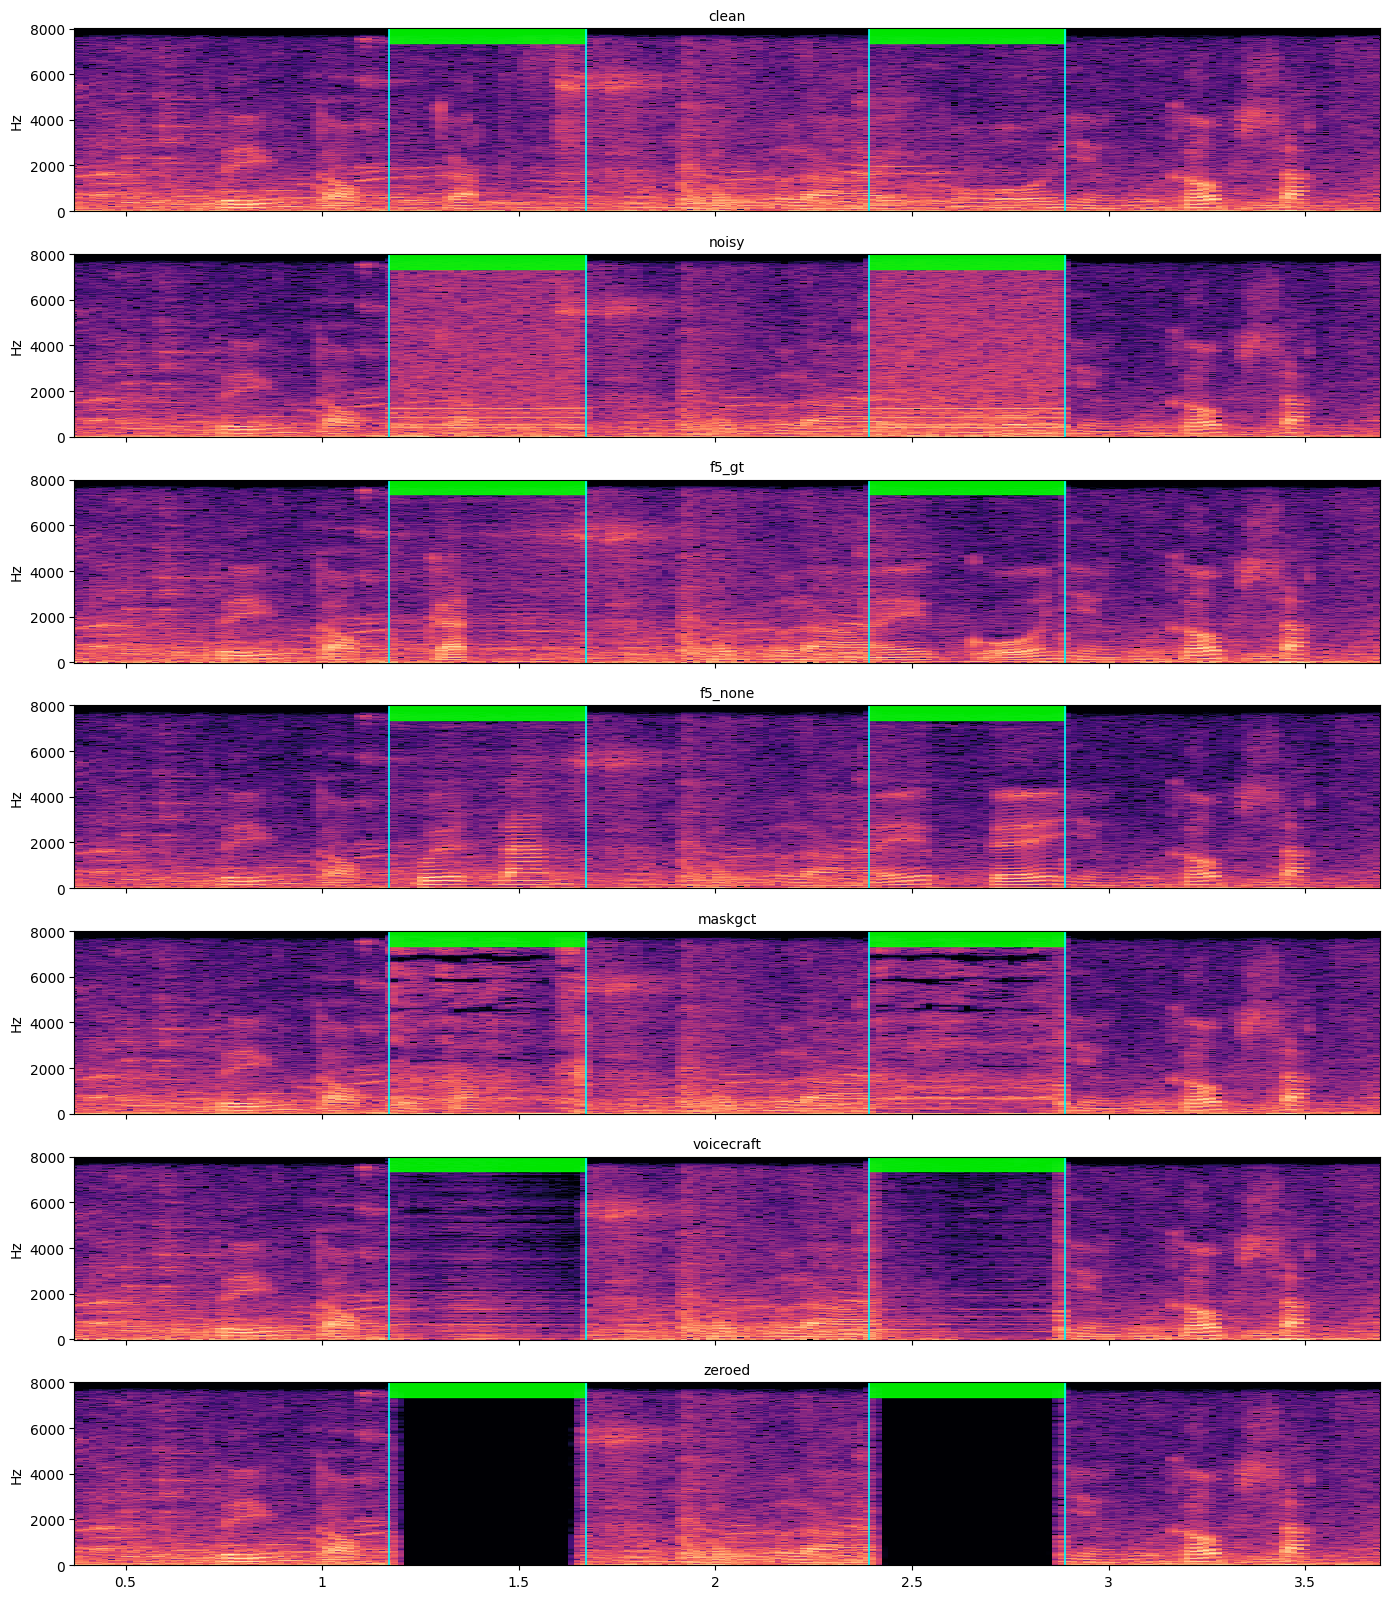

clean


noisy


f5_gt


f5_none


maskgct


voicecraft


zeroed


In [9]:
# 4.2 Listen + spectrograms (zoomed on the spans)
import matplotlib.pyplot as plt
from IPython.display import Audio, display
xlim = (max(0, spans[0][0] - 0.8), min(meta["dur"], spans[-1][1] + 0.8))
fig, axes = plt.subplots(len(sigs), 1, figsize=(14, 2.3 * len(sigs)), sharex=True)
for ax, (k, y) in zip(np.atleast_1d(axes), sigs.items()):
    U.plot_spec(ax, y, SR, k, spans, meta["gt_spans"], xlim)
plt.tight_layout(); plt.show()
for k, y in sigs.items():
    print(k); display(Audio(y, rate=SR))

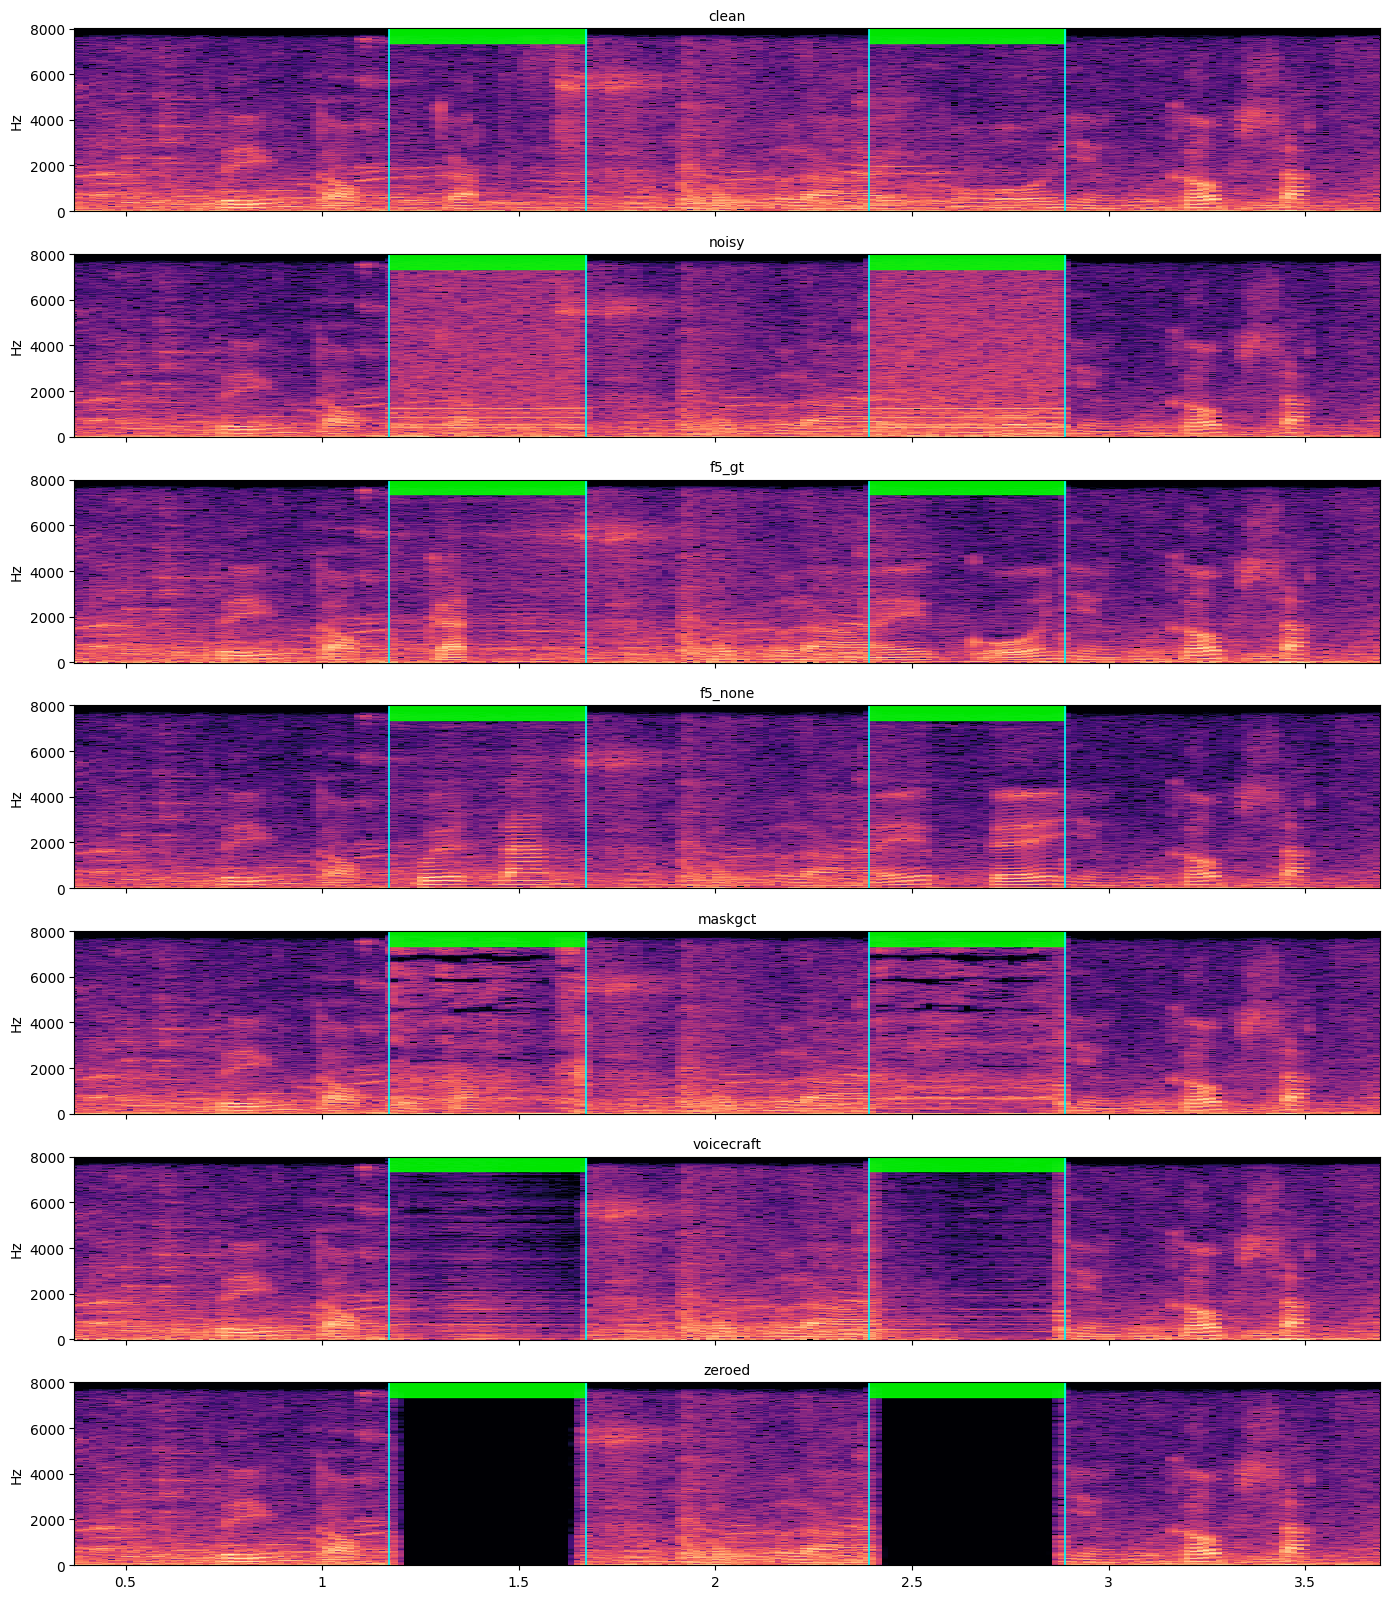

clean


noisy


f5_gt


f5_none


maskgct


voicecraft


zeroed


In [10]:
# 4.2 Listen + spectrograms (zoomed on the spans)
import matplotlib.pyplot as plt
from IPython.display import Audio, display
xlim = (max(0, spans[0][0] - 0.8), min(meta["dur"], spans[-1][1] + 0.8))
fig, axes = plt.subplots(len(sigs), 1, figsize=(14, 2.3 * len(sigs)), sharex=True)
for ax, (k, y) in zip(np.atleast_1d(axes), sigs.items()):
    U.plot_spec(ax, y, SR, k, spans, meta["gt_spans"], xlim)
plt.tight_layout(); plt.show()
for k, y in sigs.items():
    print(k); display(Audio(y, rate=SR))

In [13]:
import numpy as np, sys
sys.path.insert(0, "/content/drive/MyDrive/vi_inpaint_test")
import vi_inpaint_utils as U

meta = U.load_meta()
print(span_metrics(meta["det_spans"], meta["gt_spans"], meta["dur"]))

{'frame_precision': 0.4807692307692308, 'frame_recall': 1.0, 'frame_f1': 0.6493506493506493, 'frame_iou': 0.4807692307692308, 'span_recall': 1.0, 'span_precision': 0.5, 'pred_spans_per_gt_span': [1, 1], 'missed_s': 0.0, 'extra_s': 1.08}


In [15]:
# 5.1 Install + download weights (not pinning torch: Mega-ASR's requirements.txt would replace the preinstalled one)
%cd /content
![ -d Mega-ASR ] || git clone -q https://github.com/xzf-thu/Mega-ASR.git
!pip install -q qwen-asr peft safetensors soundfile scipy jiwer pandas librosa
!python /content/Mega-ASR/scripts/download.py
print("\n>>> Install done. REQUIRED: restart the session now, then SKIP this cell and run 5.2.")

/content
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
audiocraft 1.0.0 requires demucs, which is not installed.
audiocraft 1.0.0 requires xformers, which is not installed.
audiocraft 1.0.0 requires spacy==3.5.2, but you have spacy 3.8.18 which is incompatible.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:986: UserWarning: `local_dir_use_symlinks` parameter is deprecated and will be ignored. The process to download files to a local folder has been updated and do not rely on symlinks anymore. You only need to pass a destination folder as`local_dir`.
For more details, check out https://huggingface.co/docs/huggingface_hub/main/en/guides/download#download-files-to-local-folder.
  warnings.warn(
Fetching

In [1]:
# 5.2 Load Mega-ASR and wrap it
import sys, tempfile, soundfile as sf
from pathlib import Path
sys.path.insert(0, "/content/Mega-ASR/src")
from MegaASR.model.megaASR import MegaASR

CK = Path("/content/Mega-ASR/ckpt/Mega-ASR")
mega = MegaASR(model_path=CK / "Qwen3-ASR-1.7B", lora_dir=CK / "mega-asr-merged",
               router_checkpoint=CK / "audio_quality_router/best_acc_model.safetensors",
               routing_enabled=True, quality_threshold=0.5,
               device_map="cuda:0", backend="transformers")   # out of GPU memory? add keep_delta_on_gpu=False

LANG = "Vietnamese"   # if this raises an error, use None (automatic language detection)
MODE = "routed"       # "base" | "lora" | "routed"
def transcribe_mega(wav16):                      # float32 numpy array, 16 kHz
    with tempfile.NamedTemporaryFile(suffix=".wav") as t:   # the router needs a file path, not an array
        sf.write(t.name, wav16, 16000)
        if MODE == "base":
            return mega.infer_without_lora(t.name, language=LANG)
        if MODE == "lora":
            return mega.infer_with_lora(t.name, language=LANG)
        return mega.infer(t.name, language=LANG, return_route=True)["text"]
print("Mega-ASR loaded")

/content/Mega-ASR/src/MegaASR/model/utils/audio_quality.py:114: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Mega-ASR loaded


In [4]:
def transcribe_mega(wav16):                      # float32 numpy array, 16 kHz
    with tempfile.NamedTemporaryFile(suffix=".wav") as t:
        sf.write(t.name, wav16, 16000)
        if MODE == "base":
            r = mega.infer_without_lora(t.name, language=LANG)
        elif MODE == "lora":
            r = mega.infer_with_lora(t.name, language=LANG)
        else:
            r = mega.infer(t.name, language=LANG, return_route=True)["text"]
    while isinstance(r, (list, tuple)):          # qwen-asr returns a list even for one file
        r = r[0] if r else ""
    return str(r)

In [5]:
# 5.3 Score clean / noisy / every inpainted output with Mega-ASR in the 3 modes
import sys, glob, os, re, unicodedata, jiwer, pandas as pd, librosa
from google.colab import drive; drive.mount('/content/drive')
sys.path.insert(0, "/content/drive/MyDrive/vi_inpaint_test"); import vi_inpaint_utils as U

meta, W = U.load_meta(), U.WORK
norm = lambda s: re.sub(r"\s+", " ", re.sub(r"[^\w\s]", " ", unicodedata.normalize("NFC", s).lower())).strip()
ref = norm(meta["transcript"])

files = {"clean": f"{W}/clean_24k.wav", "noisy": f"{W}/noisy_24k.wav"}
files.update({os.path.basename(f)[:-4]: f for f in sorted(glob.glob(f"{W}/outputs_{meta['mask_source']}/*.wav"))})

rows = []
for name, f in files.items():
    y, _ = librosa.load(f, sr=16000)
    row = {"system": name}
    for MODE in ["base", "lora", "routed"]:
        h = norm(transcribe_mega(y))
        row[f"CER_{MODE}"], row[f"WER_{MODE}"], row[f"hyp_{MODE}"] = jiwer.cer(ref, h), jiwer.wer(ref, h), h
    rows.append(row)

df = pd.DataFrame(rows).set_index("system")
display(df[[c for c in df.columns if not c.startswith("hyp")]].round(3))
print("REF:", ref)
for n, r in df.iterrows():
    print(f"{n:10s} base  : {r.hyp_base}\n{'':10s} lora  : {r.hyp_lora}\n{'':10s} routed: {r.hyp_routed}")
df.to_csv(os.path.join(W, f"mega_scores_{meta['mask_source']}.csv"))

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for

,CER_base,WER_base,CER_lora,WER_lora,CER_routed,WER_routed
system,,,,,,
clean,0.140,0.222,0.349,0.667,0.349,0.667
noisy,0.279,0.444,0.372,0.667,0.372,0.667
f5_gt,0.186,0.333,0.186,0.556,0.186,0.556
f5_none,0.395,0.556,0.581,0.889,0.581,0.889
maskgct,0.326,0.556,0.512,0.778,0.512,0.778
voicecraft,0.326,0.556,0.465,0.778,0.465,0.778
zeroed,0.372,0.556,0.349,0.667,0.349,0.667


REF: tiếng cọc cạch khựng lại của những khớp sắt
clean      base  : tiếng cồng cạch vung lại của những khớp sắt
           lora  : tiến công kịch thuận lợi của những cốt sắt
           routed: tiến công kịch thuận lợi của những cốt sắt
noisy      base  : tiếng cồng trật thuận lợi của những khớp sắt
           lora  : tiến tộc gặp thuận lợi của những cốt sắt
           routed: tiến tộc gặp thuận lợi của những cốt sắt
f5_gt      base  : tiếng cọc kịch dựng lại của những cốt sắt
           lora  : tiến cột kịch dựng lại của những khốp sắt
           routed: tiến cột kịch dựng lại của những khốp sắt
f5_none    base  : tiếng cọc huyết lăn dựng lại bế những gốc sắt
           lora  : tiến tộc huyết lăng thuận lợi bế những gốc sắt
           routed: tiến tộc huyết lăng thuận lợi bế những gốc sắt
maskgct    base  : tiếng đọc được cũng là những khớp sắt
           lora  : tiến tộc được đặt tên là những cốt sắt
           routed: tiến tộc được đặt tên là những cốt sắt
voicecraft base  : tiếng cộ